In [276]:
import numpy as np
from scipy import integrate
from scipy import optimize
from scipy.stats import norm, t 
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import pandas as pd
from scipy.optimize._numdiff import approx_derivative

In [183]:
def log_likelihood(theta, y):
    n = y.shape[0]
    return theta * np.sum(y) - n * np.exp(theta)

def log_prior(theta):
    return -np.log(1 + theta**2)

def log_joint(theta, y):
    return log_likelihood(theta, y) + log_prior(theta)

def neg_log_joint(theta, y):
    return -log_joint(theta, y)

def unnorm_posterior(theta, y, m):
    return np.exp(log_joint(theta, y) - m)

def kl_integrand(theta, y, m, constant, log_g):
    log_p = log_posterior(theta, y, m, constant)

    if not np.isfinite(log_p):
        return 0.0

    p = np.exp(log_p)
    
    return (log_p - log_g(theta)) * p

def log_posterior(theta, y, m, constant):
    return log_joint(theta, y) - m - np.log(constant)


def log_skewed_laplace(theta, f, theta_map, y):
    log_joint_theta = log_joint(theta, y)
    log_joint_reflected = log_joint(2 * theta_map - theta, y)

    log_weight = log_joint_theta - logsumexp([
        log_joint_theta,
        log_joint_reflected
    ])

    return np.log(2) + f.logpdf(theta) + log_weight


In [ ]:
# consider varying n and replicates

rng = np.random.default_rng(42)
n_replicates = 500
ns = [2, 4, 8, 16, 32, 64]
v = 6

results = []

for r in range(n_replicates):
    
    for n in ns: 
    
        samples = rng.poisson(lam=1.0, size=n)
        if np.sum(samples) == 0:
            print(f"All-zero dataset: n={n}, replicate={r}")

        theta_map_opt = optimize.minimize(neg_log_joint, 1.0, (samples,), method='BFGS')
        if not theta_map_opt.success:
            print(f"Warning: MAP optimization failed for n={n}, replicate={r}")
            print(theta_map_opt.message)
        theta_map = theta_map_opt.x[0]
        m = log_joint(theta_map, samples)
        norm_constant, error = integrate.quad(unnorm_posterior, -np.inf, np.inf, args=(samples, m))
        J = (
            n * np.exp(theta_map) + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
            )

        assert J > 0

        h_theta_map = 1 / J
        scale_sq = h_theta_map * (v + 1)/v
        gaussian = norm(
            loc=theta_map,
            scale=np.sqrt(h_theta_map)
        )

        student = t(
            df=v,
            loc=theta_map,
            scale=np.sqrt(scale_sq)
        )
        log_gaussian = gaussian.logpdf
        log_student = student.logpdf
        log_skew_gaussian = lambda theta: log_skewed_laplace(theta, gaussian, theta_map, samples)
        log_skew_student = lambda theta: log_skewed_laplace(theta, student, theta_map, samples)

        if np.sum(samples) == 0:
            kl_gaussian = np.inf
            kl_gaussian_skewed = np.inf
        else:
            kl_gaussian = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_gaussian))[0]
            kl_gaussian_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_skew_gaussian))[0]
             
        kl_t = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_student))[0]
        kl_t_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_skew_student))[0]

        tol = 1e-6

        if kl_gaussian_skewed > kl_gaussian + tol:
            print(f"Gaussian inequality violated: n={n}, replicate={r}")

        if kl_t_skewed > kl_t + tol:
            print(f"Student-t inequality violated: n={n}, replicate={r}")

        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "skewed": False,
            "kl": kl_gaussian
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "skewed": True,
            "kl": kl_gaussian_skewed
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "student_t",
            "skewed": False,
            "kl": kl_t
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "student_t",
            "skewed": True,
            "kl": kl_t_skewed
            })

df = pd.DataFrame(results)
    
df

/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_66327/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


All-zero dataset: n=4, replicate=2
All-zero dataset: n=2, replicate=3
All-zero dataset: n=2, replicate=5
All-zero dataset: n=2, replicate=15
All-zero dataset: n=2, replicate=20
All-zero dataset: n=2, replicate=21
All-zero dataset: n=2, replicate=24
All-zero dataset: n=2, replicate=25
All-zero dataset: n=2, replicate=40
All-zero dataset: n=4, replicate=44
All-zero dataset: n=2, replicate=52
All-zero dataset: n=2, replicate=53
All-zero dataset: n=2, replicate=66
All-zero dataset: n=2, replicate=76
All-zero dataset: n=2, replicate=98
All-zero dataset: n=2, replicate=103
All-zero dataset: n=2, replicate=114
All-zero dataset: n=2, replicate=115
All-zero dataset: n=2, replicate=118
All-zero dataset: n=4, replicate=126
All-zero dataset: n=2, replicate=162
All-zero dataset: n=2, replicate=167
All-zero dataset: n=2, replicate=169
All-zero dataset: n=4, replicate=169
All-zero dataset: n=2, replicate=174
All-zero dataset: n=2, replicate=180
All-zero dataset: n=2, replicate=186
All-zero dataset: n

,n,replicate,family,skewed,kl
0,2,0,gaussian,False,0.020374
1,2,0,gaussian,True,0.010099
2,2,0,student_t,False,0.032575
3,2,0,student_t,True,0.022299
4,4,0,gaussian,False,0.009724
...,...,...,...,...,...
11995,32,499,student_t,True,0.038567
11996,64,499,gaussian,False,0.002510
11997,64,499,gaussian,True,0.000074
11998,64,499,student_t,False,0.042965


In [215]:
df.to_csv("simulations_laplace_poisson", index=False)

In [ ]:
def variational_distribution(params, family, v=6):
    mu, ro = params
    if family == 'gaussian':
        return norm(loc=mu, scale=np.exp(ro))
    else:
        return t(df=v, loc=mu, scale=np.exp(ro))      

def hellinger_objective_mc(params, family, y, m, rng, M=1000, v=6):
    sampling_distr = variational_distribution(params, family, v)
    thetas = sampling_distr.rvs(size=M, random_state=rng)
    log_g = log_joint(thetas, y) - m
    log_q = sampling_distr.logpdf(thetas)
    mc_estimate = np.mean(np.exp(0.5 * (log_g - log_q)))
    return mc_estimate

def hellinger_integrand(theta, q, y, m):
    log_g = log_joint(theta, y) - m
    log_q = q.logpdf(theta)
    return np.exp(0.5 * (log_g + log_q))

def hellinger_objective_quad(params, family, y, m, v=6):
    q = variational_distribution(params, family, v)

    value, error = integrate.quad(
        hellinger_integrand,
        -np.inf,
        np.inf,
        args=(q, y, m)
    )

    return value

def calculate_score(params, family, y, m, rng, M=1000, v=6):
    mu, ro = params
    sampling_distr = variational_distribution(params, family, v)
    thetas = sampling_distr.rvs(size=M, random_state=rng)
    log_g = log_joint(thetas, y) - m
    log_q = sampling_distr.logpdf(thetas)
    var = np.exp(2 * ro)
    if family == 'gaussian':
        der_mu = (thetas - mu) / (var) # (M,)
        der_ro = -1 + ((thetas - mu)**2 / (var)) # (M,)
    else: 
        der_mu = (thetas - mu) * (v + 1) / (v * var + (thetas - mu)**2)
        der_ro = -1 + ((v + 1) * (thetas - mu)**2) / (v * var + (thetas - mu)**2)
    gradient = np.stack([der_mu, der_ro]) # (2, M)
    return 0.5 * np.mean(gradient * np.exp (0.5 * (log_g - log_q)), axis=1)

def fit_bbvi(
        initial_params,
        family,
        y,
        m,
        rng,
        M=1000,
        v=6,
        learning_rate=0.01,
        n_iterations=1000,
             ):
    # start from some initial parameters
    # find gradient and update parameter (p_{k + 1} = p_k + learning rate * gradient)
    # save everything in a history and return that
    params = initial_params.copy()
    history = [initial_params.copy()]
    for iteration in range(n_iterations):
        gradient = calculate_score(params, family, y, m, rng, M=M, v=v)
        params = params + learning_rate * gradient
        history.append(params.copy())

    return params, np.array(history)



In [ ]:
rng_data = np.random.default_rng(42)
rng_vi = np.random.default_rng(123)

n = 5
v = 6
theta_true = 0.0

samples = rng_data.poisson(
    lam=np.exp(theta_true),
    size=n
)

result = optimize.minimize(neg_log_joint, 1.0, args=(samples,), method='BFGS')
theta_map = result.x[0]
m = log_joint(theta_map, samples)
J = (
    n * np.exp(theta_map)
    + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
)


In [312]:
families = ['gaussian', 'student_t']

initializations = {
    'gaussian': {
        'laplace': np.array([theta_map, -0.5 * np.log(J)]),
        'other': np.array([0.0, -3.0])
    },
    'student_t': {
        'laplace': np.array([theta_map, 0.5 * np.log((v + 1) / (v * J))]),
        'other': np.array([0.0, -3.0])
    }
}

results = {}
for family in families:
    results[family] = {}
    for init_name, initial_params in initializations[family].items():
        rng = np.random.default_rng(123)
        params_opt, history = fit_bbvi(
                initial_params,
                family,
                samples,
                m,
                rng_vi,
                M=1000,
                v=6,
                learning_rate=0.01,
                n_iterations=5000
            )
        J_initial = hellinger_objective_quad(initial_params, family, samples, m, v=v)
        J_final = hellinger_objective_quad(params_opt, family, samples, m, v=v)
        results[family][init_name] = {
            "initial_params": initial_params.copy(),
            "params_opt": params_opt,
            "history": history,
            "J_initial": J_initial,
            "J_final": J_final
        }

/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_66327/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


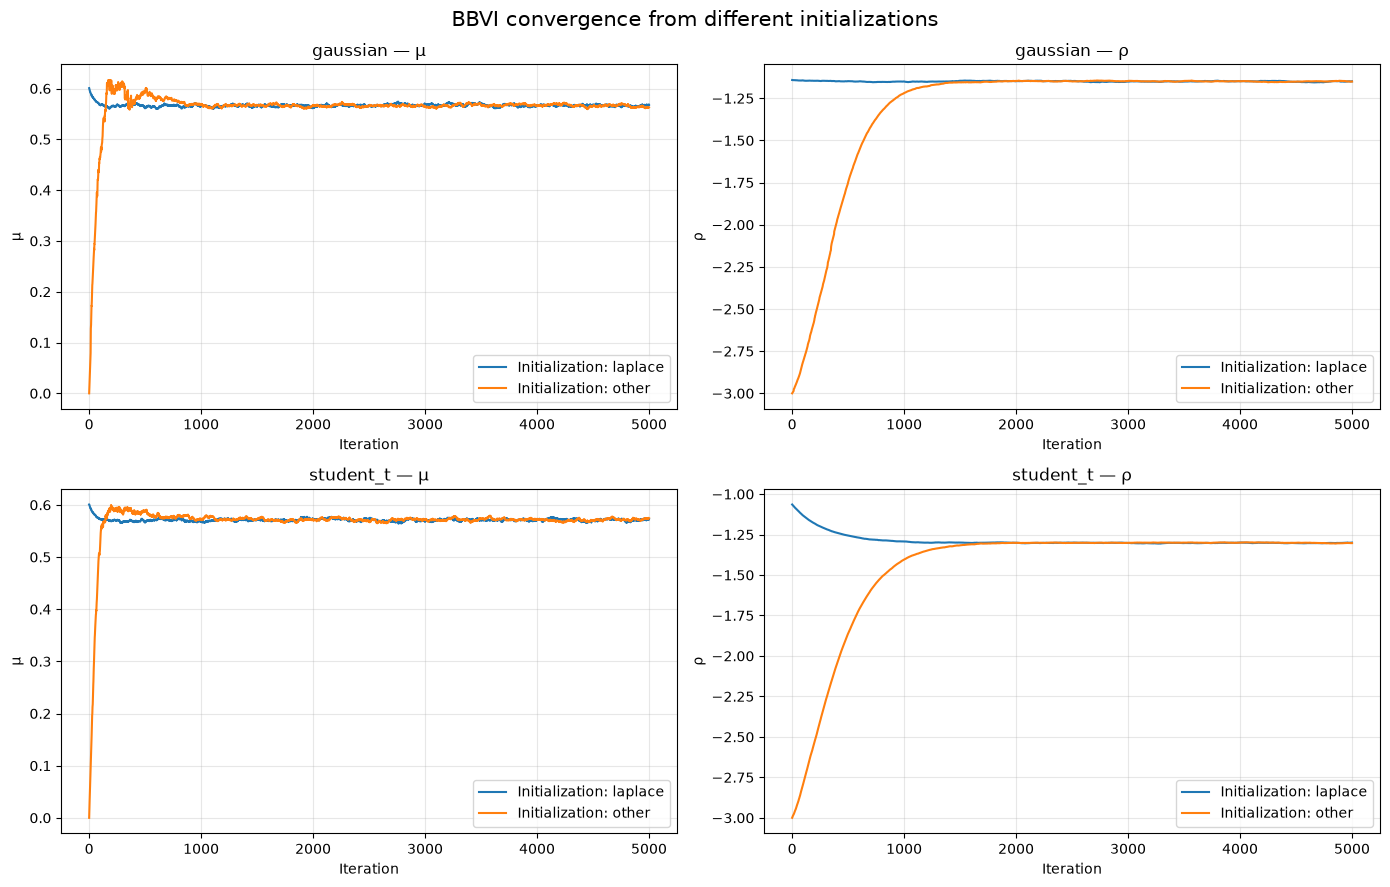

In [313]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, family in enumerate(families):
    for j, parameter in enumerate(["μ", "ρ"]):

        ax = axes[i, j]

        for init_name, result in results[family].items():
            history = result["history"]

            ax.plot(
                history[:, j],
                label=f"Initialization: {init_name}",
                linewidth=1.5
            )

        ax.set_title(f"{family} — {parameter}")
        ax.set_xlabel("Iteration")
        ax.set_ylabel(parameter)
        ax.grid(alpha=0.3)
        ax.legend()

plt.suptitle("BBVI convergence from different initializations", fontsize=15)
plt.tight_layout()
plt.show()

In [314]:
import pandas as pd

rows = []

for family in families:
    for init_name, result in results[family].items():
        rows.append({
            "family": family,
            "initialization": init_name,
            "mu_opt": result["params_opt"][0],
            "scale_opt": np.exp(result["params_opt"][1]),
            "J_initial": result["J_initial"],
            "J_final": result["J_final"],
            "improvement": result["J_final"] - result["J_initial"]
        })

summary_df = pd.DataFrame(rows)

print(summary_df.to_string(index=False))

   family initialization   mu_opt  scale_opt  J_initial  J_final  improvement
 gaussian        laplace 0.567889   0.316851   0.890521 0.891855     0.001335
 gaussian          other 0.563043   0.316417   0.228012 0.891845     0.663833
student_t        laplace 0.572720   0.272592   0.877264 0.888068     0.010804
student_t          other 0.574605   0.271736   0.271988 0.888057     0.616069
